Paquetes necesarios

In [23]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv
import seaborn as sns
import random

from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)


TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



Detectamos las monedas umbralizando los contornos, detectando los distintos tamaños de las mismas. Cuando el usuario hace clic en la moneda de 1€, el programa usa esta misma moneda de referencia para clasificar las otras por tamaño. Finalmente indica el valor de cada moneda y muestra el total en la parte superior izquierda.

In [24]:
# Diámetros reales de las monedas en mm: {valor en euros: diámetro}
MONEDAS_MM = {
    0.01: 16.25,
    0.02: 18.75,
    0.05: 21.25,
    0.10: 19.75,
    0.20: 22.25,
    0.50: 24.35,   # valor del enunciado
    1.00: 23.25,
    2.00: 25.75,
}

DIAMETRO_1EURO = MONEDAS_MM[1.00]
TOLERANCIA_MM = 1.5   # si ninguna moneda se parece a menos de esto, se marca como "?"


def detectar_monedas(img_bgr, area_min=500, circularidad_min=0.8):
    """Devuelve una lista de monedas (x, y, radio_en_pixeles) y la imagen binaria usada."""
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (7, 7), 0)

    # Otsu invertido: monedas en blanco, fondo en negro
    _, binaria = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # El fondo suele ser la parte más grande: si hay más blanco que negro, invertimos
    if np.mean(binaria) > 127:
        binaria = 255 - binaria

    # Limpieza: cerrar huecos dentro de las monedas y quitar ruido pequeño
    kernel = np.ones((5, 5), np.uint8)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, kernel)
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, kernel)

    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    monedas = []
    for c in contornos:
        area = cv2.contourArea(c)
        if area < area_min:
            continue
        perimetro = cv2.arcLength(c, True)
        # Circularidad: 1 para un círculo perfecto, menor para otras formas
        circularidad = 4 * np.pi * area / (perimetro ** 2)
        if circularidad < circularidad_min:
            continue
        (x, y), _ = cv2.minEnclosingCircle(c)
        radio = np.sqrt(area / np.pi)   # radio a partir del área
        monedas.append((x, y, radio))
    return monedas, binaria


def moneda_en_punto(monedas, punto):
    """Índice de la moneda que contiene al punto (x, y), o None si no hay ninguna."""
    mejor, mejor_dist = None, None
    for i, (x, y, r) in enumerate(monedas):
        dist = np.hypot(x - punto[0], y - punto[1])
        if dist <= r and (mejor_dist is None or dist < mejor_dist):
            mejor, mejor_dist = i, dist
    return mejor


def calibrar(radio_px, diametro_mm=DIAMETRO_1EURO):
    """Milímetros que mide un píxel, sabiendo el diámetro real de una moneda."""
    return diametro_mm / (2 * radio_px)


def clasificar_moneda(radio_px, mm_por_px):
    """Devuelve (valor, diametro_mm). Si no encaja con ninguna moneda, valor es None."""
    diametro = 2 * radio_px * mm_por_px
    valor = min(MONEDAS_MM, key=lambda v: abs(MONEDAS_MM[v] - diametro))
    if abs(MONEDAS_MM[valor] - diametro) > TOLERANCIA_MM:
        return None, diametro
    return valor, diametro


def procesar_monedas(img_bgr, monedas, mm_por_px):
    """Dibuja las monedas sobre la imagen. Devuelve (imagen, total en euros, conteo por valor)."""
    salida = img_bgr.copy()
    total = 0.0
    conteo = Counter()
    for (x, y, r) in monedas:
        centro = (int(x), int(y))
        escala_texto = max(0.5, r / 50)
        if mm_por_px is None:
            # Sin calibrar: solo marcamos las monedas en amarillo
            cv2.circle(salida, centro, int(r), (0, 255, 255), 2)
            continue
        valor, diametro = clasificar_moneda(r, mm_por_px)
        if valor is None:
            cv2.circle(salida, centro, int(r), (0, 0, 255), 2)
            texto = "?"
        else:
            total += valor
            conteo[valor] += 1
            cv2.circle(salida, centro, int(r), (0, 255, 0), 2)
            texto = f"{valor:.2f}"
        cv2.putText(salida, texto, (centro[0] - int(r / 2), centro[1]),
                    cv2.FONT_HERSHEY_SIMPLEX, escala_texto, (255, 0, 0), 2)
    return salida, round(total, 2), conteo


def pedir_clic(img_bgr, titulo="Haz clic en una moneda de 1 euro (ESC para cancelar)"):
    """Muestra la imagen y devuelve el punto (x, y) donde el usuario hace clic."""
    puntos = []

    def raton(evento, x, y, flags, param):
        if evento == cv2.EVENT_LBUTTONDOWN:
            puntos.append((x, y))

    cv2.namedWindow(titulo, cv2.WINDOW_NORMAL)
    cv2.setMouseCallback(titulo, raton)
    while len(puntos) == 0:
        cv2.imshow(titulo, img_bgr)
        if cv2.waitKey(20) & 0xFF == 27:   # ESC
            break
    cv2.destroyAllWindows()
    cv2.waitKey(1)
    return puntos[0] if puntos else None


Monedas detectadas: 8
Radio de la moneda de referencia: 93.1 px
Escala: 0.1249 mm/píxel
  1 x 0.01 €
  1 x 0.02 €
  1 x 0.05 €
  1 x 0.10 €
  1 x 0.20 €
  1 x 0.50 €
  1 x 1.00 €
  1 x 2.00 €
TOTAL: 3.88 €


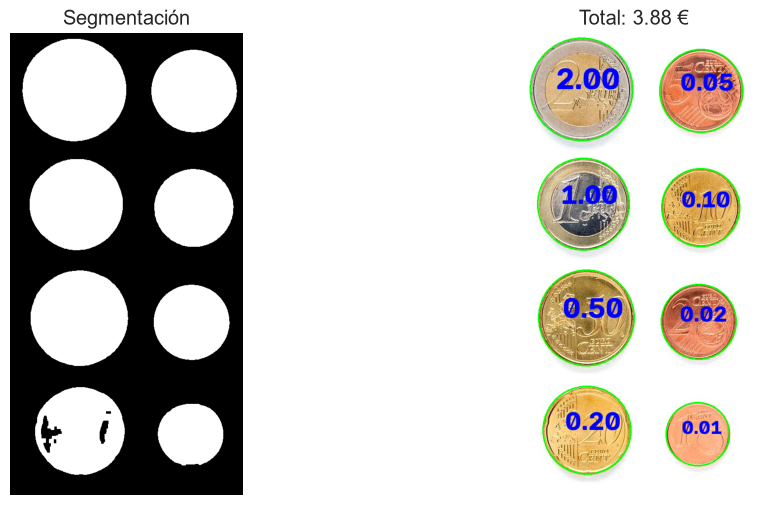

In [25]:
# --- Imagen ideal ---
img_monedas = cv2.imread('Monedas.jpg')
if img_monedas is None:
    raise FileNotFoundError("No se encuentra Monedas.jpg (debe estar junto al notebook)")

monedas, binaria = detectar_monedas(img_monedas)
print('Monedas detectadas:', len(monedas))

# 1) Clic en una moneda de 1 euro para calibrar
punto = pedir_clic(img_monedas)
# Si no puedes usar la ventana de OpenCV, descomenta y pon las coordenadas (x, y) de un 1 euro:
# punto = (350, 420)

idx = moneda_en_punto(monedas, punto) if punto else None
if idx is None:
    raise ValueError("El clic no cayó sobre ninguna moneda detectada")

# 2) Escala píxeles -> mm
radio_ref = monedas[idx][2]
mm_por_px = calibrar(radio_ref)
print(f'Radio de la moneda de referencia: {radio_ref:.1f} px')
print(f'Escala: {mm_por_px:.4f} mm/píxel')

# 3) Clasificar todas las monedas y sumar
img_resultado, total, conteo = procesar_monedas(img_monedas, monedas, mm_por_px)

for valor in sorted(conteo):
    print(f'  {conteo[valor]} x {valor:.2f} €')
print(f'TOTAL: {total:.2f} €')

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.axis("off")
plt.imshow(binaria, cmap='gray')
plt.title('Segmentación')
plt.subplot(1, 2, 2)
plt.axis("off")
plt.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
plt.title(f'Total: {total:.2f} €')
plt.show()


Demostrador en vivo (cámara)

Usa las mismas funciones de arriba. Controles de la ventana:
- Clic sobre una moneda de 1 € → calibra (la escala se guarda hasta que la cambies).
- r → borrar la calibración.
- q o ESC → salir.

Antes de calibrar las monedas se marcan en amarillo. Tras calibrar: verde = moneda reconocida, rojo con "?" = objeto que no encaja con ninguna moneda.

In [26]:
def demo_camara(indice_camara=0):
    cap = cv2.VideoCapture(indice_camara)
    if not cap.isOpened():
        print("No se pudo abrir la cámara")
        return

    estado = {'clic': None, 'mm_por_px': None}

    def raton(evento, x, y, flags, param):
        if evento == cv2.EVENT_LBUTTONDOWN:
            estado['clic'] = (x, y)

    ventana = 'Monedas en vivo'
    cv2.namedWindow(ventana)
    cv2.setMouseCallback(ventana, raton)

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        # El área mínima depende de la resolución de la cámara
        alto, ancho = frame.shape[:2]
        monedas, _ = detectar_monedas(frame, area_min=int(0.002 * alto * ancho))

        # Si hubo clic, intentamos calibrar con la moneda pulsada
        if estado['clic'] is not None:
            idx = moneda_en_punto(monedas, estado['clic'])
            if idx is not None:
                estado['mm_por_px'] = calibrar(monedas[idx][2])
            estado['clic'] = None

        salida, total, conteo = procesar_monedas(frame, monedas, estado['mm_por_px'])

        if estado['mm_por_px'] is None:
            texto = "Haz clic en una moneda de 1 euro para calibrar"
        else:
            texto = f"Total: {total:.2f} EUR"
        cv2.putText(salida, texto, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4)
        cv2.putText(salida, texto, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        cv2.imshow(ventana, salida)

        tecla = cv2.waitKey(1) & 0xFF
        if tecla in (ord('q'), 27):
            break
        if tecla == ord('r'):
            estado['mm_por_px'] = None

    cap.release()
    cv2.destroyAllWindows()
    cv2.waitKey(1)


demo_camara(0)


El objetivo de la siguiente tarea, descrita más abajo, es desarrollar tu propio clasificador basado únicamente en heurísticas basadas en características geométricas y/o de apariencia, a partir de las imágenes completas de las partículas de cada tipo, debiendo mostrar la bondad del clasificador haciendo uso de métricas para ello sobre las anotaciones de la imagen de test *MPs_test.png*. La siguiente celda obtiene varias métricas para un conjunto de datos imaginario (y con etiquetas aleatorias). Si bien las trataremos con más detalle en teoría, muestro un repertorio de ellas, dando más peso a la matriz de confusión. La ejecución de la celda requiere instalar el paquete scikit-learn.

¿Qué es una matriz de confusión?
Se utiliza para mostrar el comportamiento de un clasificador para las distintas clases conocidas, se relacionan las etiquetas de las muestras anotadas frente a las predichas por el clasificador. Se busca una matriz diagonal, pero la perfección es infrecuente.

El siguiente ejemplo, muestra el modo de obtener la matriz de confusión para un hipotético problema con cuatro clases, y valores de anotación (variable y) y predicción (variable y_pred) obtenidos de forma aleatoria.

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno


## Solución Tarea 2 (versión mejorada): Clasificación de microplásticos (FRA / PEL / TAR)

**Qué cambia respecto a la versión anterior y por qué**

1. **Segmentación por distancia de color al fondo (CIELAB)**, no por umbral de gris. El umbral adaptativo sobre gris solo ve el *brillo*: los fragmentos blancos/translúcidos y los pellets claros tienen casi el mismo gris que el fondo del escáner y desaparecían. Ahora se estima el fondo local (mediana con kernel grande, que absorbe viñeteo y bandas del escáner) y se mide la distancia euclídea en Lab (≈ ΔE) de cada píxel a ese fondo. Cuenta tanto un cambio de luminosidad como de tono/saturación.
2. **Umbral por histéresis** (bajo/alto): el alto garantiza que hay partícula de verdad; el bajo recupera sus bordes pálidos sin arrastrar ruido.
3. **Características de color relativas al fondo** (ΔL, croma, a, b, desviación de L...) en Lab, en vez de gris/saturación absolutos. Así el clasificador es menos sensible a que el entrenamiento sea cámara y el test escáner.
4. **Entrenamiento con las imágenes completas** (`*-03-olympus-*.JPG`, ~70/55/53 partículas por clase en lugar de 10/15/8) **reescaladas a la resolución del test**, de modo que los parámetros de segmentación (kernels, área mínima) significan lo mismo en entrenamiento y en test.
5. **kNN balanceado con k=5** (sin clase dominante en el entrenamiento) y métricas que cuentan como fallo las partículas no segmentadas.

In [27]:
#%pip install scikit-image

In [28]:
import pandas as pd
from scipy import ndimage as ndi
from skimage.filters import apply_hysteresis_threshold

CLASES = ['FRA', 'PEL', 'TAR']

# ---------------- Parámetros de segmentación ----------------
UMBRAL_BAJO  = 10     # ΔE mínimo para pertenecer a una partícula (recupera bordes pálidos)
UMBRAL_ALTO  = 14     # ΔE que debe alcanzar al menos un píxel del blob (descarta ruido/sombras)
KERNEL_FONDO = 41     # tamaño (px) de la mediana que estima el fondo; > partícula más grande
AREA_MIN_MP  = 80     # px a la resolución del test (~1/5 del área mediana de un pellet)
ESCALA_TRAIN = 0.56   # factor que lleva las fotos de entrenamiento (2576x1932) a la resolución del test

NOMBRES_CARACT = ['area', 'perimetro', 'compacidad', 'area_contenedor', 'ratio_contenedor',
                  'ratio_elipse', 'ratio_distancias', 'solidez', 'circularidad',
                  'dL', 'da', 'db', 'croma', 'sat_rel', 'std_L', 'L_min']

# Características usadas: forma (invariantes a escala) + color relativo al fondo
CARACT_USADAS = ['compacidad', 'area_contenedor', 'ratio_contenedor', 'ratio_elipse',
                 'ratio_distancias', 'solidez', 'circularidad',
                 'dL', 'da', 'db', 'croma', 'std_L', 'L_min']
IDX_USADAS = [NOMBRES_CARACT.index(n) for n in CARACT_USADAS]


def distancia_al_fondo(img_bgr, kernel=KERNEL_FONDO):
    """Distancia de color (Lab) de cada píxel al fondo local. Devuelve (distancia, lab, fondo_lab)."""
    lab = cv2.cvtColor(cv2.GaussianBlur(img_bgr, (3, 3), 0), cv2.COLOR_BGR2LAB).astype(np.float32)
    s = 4                                               # estimamos el fondo en baja resolución (rápido)
    pequena = cv2.resize(lab, None, fx=1 / s, fy=1 / s, interpolation=cv2.INTER_AREA)
    k = (kernel // s) | 1                               # kernel impar
    fondo = np.stack([cv2.medianBlur(np.clip(pequena[..., i], 0, 255).astype(np.uint8), k)
                      for i in range(3)], axis=-1).astype(np.float32)
    fondo = cv2.resize(fondo, (img_bgr.shape[1], img_bgr.shape[0]), interpolation=cv2.INTER_LINEAR)
    dist = np.sqrt(((lab - fondo) ** 2).sum(axis=2))
    return dist, lab, fondo


def segmentar_particulas(img_bgr, area_min=AREA_MIN_MP, bajo=UMBRAL_BAJO, alto=UMBRAL_ALTO,
                         kernel=KERNEL_FONDO):
    """Devuelve (contornos, binaria, distancia, lab, fondo)."""
    dist, lab, fondo = distancia_al_fondo(img_bgr, kernel)
    binaria = apply_hysteresis_threshold(dist, bajo, alto)
    binaria = ndi.binary_fill_holes(binaria).astype(np.uint8)          # partículas translúcidas con centro claro
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contornos = [c for c in contornos if cv2.contourArea(c) >= area_min]
    return contornos, binaria * 255, dist, lab, fondo


def extraer_caracteristicas(c, lab, fondo):
    """Características de un contorno (mismo orden que NOMBRES_CARACT)."""
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)
    compacidad = perimetro ** 2 / area
    circularidad = 4 * np.pi * area / perimetro ** 2

    x, y, w, h = cv2.boundingRect(c)
    area_contenedor = area / (w * h)
    ratio_contenedor = min(w, h) / max(w, h)

    if len(c) >= 5:
        (_, (e1, e2), _) = cv2.fitEllipse(c)
        ratio_elipse = max(e1, e2) / max(min(e1, e2), 1e-3)
    else:
        ratio_elipse = 1.0

    M = cv2.moments(c)
    cx, cy = M['m10'] / M['m00'], M['m01'] / M['m00']
    p = c[:, 0, :].astype(float)
    dist_c = np.hypot(p[:, 0] - cx, p[:, 1] - cy)
    ratio_distancias = dist_c.min() / dist_c.max()

    solidez = area / max(cv2.contourArea(cv2.convexHull(c)), 1)

    # Color: solo píxeles del interior (erosión) para que el borde difuminado no contamine
    mascara = np.zeros((h, w), np.uint8)
    cv2.drawContours(mascara, [c - np.array([x, y])], -1, 255, -1)
    r = max(1, int(round(np.sqrt(area) / 10)))
    interior = cv2.erode(mascara, np.ones((2 * r + 1, 2 * r + 1), np.uint8))
    if interior.sum() == 0:
        interior = mascara
    sel = interior > 0
    px = lab[y:y + h, x:x + w][sel]
    bg = fondo[y:y + h, x:x + w][sel]
    dif = (px - bg).mean(axis=0)                               # ΔL, Δa, Δb respecto al fondo local
    croma = np.hypot(px[:, 1].mean() - 128, px[:, 2].mean() - 128)
    sat_rel = np.hypot(px[:, 1] - bg[:, 1], px[:, 2] - bg[:, 2]).mean()
    std_L = px[:, 0].std()
    L_min = px[:, 0].min() - bg[:, 0].mean()

    return [area, perimetro, compacidad, area_contenedor, ratio_contenedor, ratio_elipse,
            ratio_distancias, solidez, circularidad, dif[0], dif[1], dif[2], croma, sat_rel, std_L, L_min]


def caracteristicas_imagen(img_bgr, escala=1.0):
    """Reescala (si hace falta), segmenta y devuelve (contornos, X, binaria, imagen_usada)."""
    if escala != 1.0:
        img_bgr = cv2.resize(img_bgr, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
    contornos, binaria, _, lab, fondo = segmentar_particulas(img_bgr)
    X = np.array([extraer_caracteristicas(c, lab, fondo) for c in contornos])
    return contornos, X, binaria, img_bgr


def leer_anotaciones(ruta_csv):
    """Devuelve una lista de (etiqueta, x_min, y_min, x_max, y_max)."""
    anotaciones = []
    with open(ruta_csv, newline="") as f:
        for fila in csv.DictReader(f):
            x1, y1, x2, y2 = map(int, [fila["x_min"], fila["y_min"], fila["x_max"], fila["y_max"]])
            anotaciones.append((fila["label"], x1, y1, x2, y2))
    return anotaciones


def centroide(c):
    M = cv2.moments(c)
    if M['m00'] == 0:
        x, y, w, h = cv2.boundingRect(c)
        return x + w / 2, y + h / 2
    return M['m10'] / M['m00'], M['m01'] / M['m00']


def emparejar(contornos, anotaciones):
    """Por cada anotación, índice del contorno más grande cuyo centroide cae en su caja (o None)."""
    centros = [centroide(c) for c in contornos]
    areas = [cv2.contourArea(c) for c in contornos]
    pares = []
    for (_, x1, y1, x2, y2) in anotaciones:
        cand = [i for i, (cx, cy) in enumerate(centros) if x1 <= cx <= x2 and y1 <= cy <= y2]
        pares.append(max(cand, key=lambda i: areas[i]) if cand else None)
    return pares

### Comparación de métodos de segmentación sobre `MPs_test.jpg`

Para cada método se cuenta cuántas de las 120 partículas anotadas tienen un contorno cuyo centroide cae dentro de su caja (detección). Es la comprobación directa de si se pierden las partículas claras.

In [29]:
def segmentar_gris(img_bgr, metodo, area_min=AREA_MIN_MP):
    """Métodos antiguos (solo gris) para comparar."""
    gris = cv2.GaussianBlur(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    if metodo == 'adaptativo':
        b = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 51, 10)
    else:
        _, b = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        if np.mean(b) > 127:
            b = 255 - b
    k = np.ones((3, 3), np.uint8)
    b = cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    cs, _ = cv2.findContours(b, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c for c in cs if cv2.contourArea(c) >= area_min]


img_test = cv2.imread('MPs_test.jpg')
if img_test is None:
    raise FileNotFoundError("No se encuentra MPs_test.jpg")
anotaciones = leer_anotaciones('MPs_test_bbs.csv')

candidatos = {
    'gris + adaptativo (anterior)': segmentar_gris(img_test, 'adaptativo'),
    'gris + Otsu':                  segmentar_gris(img_test, 'otsu'),
    'Lab dist. al fondo + histéresis (nuevo)': segmentar_particulas(img_test)[0],
}
for nombre, cs in candidatos.items():
    detectadas = sum(p is not None for p in emparejar(cs, anotaciones))
    print(f'{nombre:45s} contornos: {len(cs):4d} | anotaciones detectadas: {detectadas:3d}/{len(anotaciones)}')

gris + adaptativo (anterior)                  contornos:   64 | anotaciones detectadas:  60/120
gris + Otsu                                   contornos:   37 | anotaciones detectadas:  37/120
Lab dist. al fondo + histéresis (nuevo)       contornos:  118 | anotaciones detectadas: 116/120


### Entrenamiento con las imágenes completas (FRA / PEL / TAR)

Las fotos de entrenamiento (cámara, 2576×1932) tienen las partículas ~1,8 veces más grandes en píxeles que el escáner del test, por eso se reescalan con `ESCALA_TRAIN` antes de segmentar. Así `AREA_MIN_MP`, el kernel del fondo y la morfología valen igual en ambas.

FRA: 94 partículas segmentadas
PEL: 56 partículas segmentadas
TAR: 55 partículas segmentadas


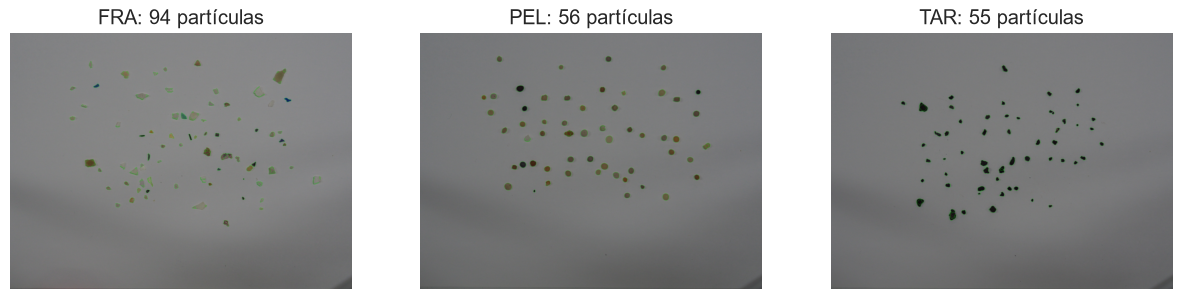


                         FRA       PEL       TAR
              area    545.74   1489.90    971.10
         perimetro    113.27    152.35    136.88
        compacidad     28.66     17.61     20.74
   area_contenedor      0.54      0.72      0.65
  ratio_contenedor      0.77      0.92      0.83
      ratio_elipse      1.78      1.15      1.44
  ratio_distancias      0.36      0.74      0.54
           solidez      0.83      0.94      0.92
      circularidad      0.58      0.82      0.72
                dL    -30.63    -23.46    -84.71
                da     -0.18      1.59      0.87
                db      6.42      6.90      0.11
             croma     10.51     13.43      1.34
           sat_rel      8.34      7.42      1.53
             std_L      6.76      6.47     20.66
             L_min    -43.74    -35.50   -101.43


In [30]:
imagenes_train = {'FRA': 'fragment-03-olympus-10-01-2020.JPG',
                  'PEL': 'pellet-03-olympus-10-01-2020.JPG',
                  'TAR': 'tar-03-olympus-10-01-2020.JPG'}

X_train, y_train = [], []
plt.figure(figsize=(15, 4))
for i, clase in enumerate(CLASES):
    img_c = cv2.imread(imagenes_train[clase])
    if img_c is None:
        raise FileNotFoundError(f"No se encuentra {imagenes_train[clase]}")
    contornos_c, X_c, binaria_c, img_esc = caracteristicas_imagen(img_c, ESCALA_TRAIN)
    print(f'{clase}: {len(contornos_c)} partículas segmentadas')
    X_train.extend(X_c)
    y_train.extend([clase] * len(X_c))

    vis = img_esc.copy()
    cv2.drawContours(vis, contornos_c, -1, (0, 255, 0), 1)
    plt.subplot(1, 3, i + 1)
    plt.axis("off")
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.title(f'{clase}: {len(contornos_c)} partículas')
plt.show()

X_train = np.array(X_train)
y_train = np.array(y_train)

print()
print(f'{"":>18}' + ''.join(f'{c:>10}' for c in CLASES))
for j, nombre in enumerate(NOMBRES_CARACT):
    medias = [X_train[y_train == c, j].mean() for c in CLASES]
    print(f'{nombre:>18}' + ''.join(f'{m:>10.2f}' for m in medias))

In [31]:
escalador = StandardScaler()
X_train_n = escalador.fit_transform(X_train[:, IDX_USADAS])

clasificador = KNeighborsClassifier(n_neighbors=5)
clasificador.fit(X_train_n, y_train)

# Orientativo (validación cruzada sobre el propio entrenamiento, NO es la métrica final)
from sklearn.model_selection import cross_val_score
print('Accuracy CV 5-fold en entrenamiento:',
      cross_val_score(KNeighborsClassifier(n_neighbors=5), X_train_n, y_train, cv=5).mean().round(3))

Accuracy CV 5-fold en entrenamiento: 0.859


### Evaluación sobre MPs_test.jpg

Se dan dos lecturas: sobre las partículas **detectadas** (clasificación pura) y sobre **todas las anotadas**, contando como error las que la segmentación no encontró (lo que de verdad cuesta una mala segmentación).

Partículas segmentadas: 118 | Partículas anotadas: 120
Anotaciones emparejadas: 116 | Sin partícula segmentada: 4

Sobre partículas detectadas:  Accuracy=0.793  Precision=0.794  Recall=0.793  F1=0.793
Sobre TODAS las anotadas (no detectada = fallo): Accuracy=0.767

              precision    recall  f1-score   support

         FRA       0.81      0.84      0.82        64
         PEL       0.72      0.70      0.71        37
         TAR       0.92      0.80      0.86        15

    accuracy                           0.79       116
   macro avg       0.82      0.78      0.80       116
weighted avg       0.79      0.79      0.79       116



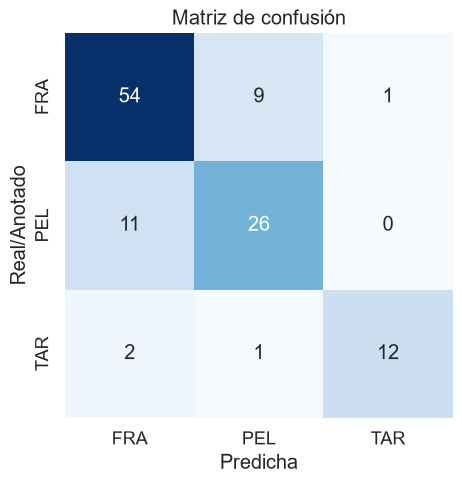

In [32]:
contornos_t, X_t, binaria_t, _ = caracteristicas_imagen(img_test)
print(f'Partículas segmentadas: {len(contornos_t)} | Partículas anotadas: {len(anotaciones)}')

pred_todas = clasificador.predict(escalador.transform(X_t[:, IDX_USADAS]))
pares = emparejar(contornos_t, anotaciones)

y_real, y_pred, y_real_all, y_pred_all = [], [], [], []
no_detectadas = 0
for (etiqueta, *_), idx in zip(anotaciones, pares):
    y_real_all.append(etiqueta)
    if idx is None:
        no_detectadas += 1
        y_pred_all.append('NO_DET')
        continue
    y_real.append(etiqueta); y_pred.append(pred_todas[idx]); y_pred_all.append(pred_todas[idx])
print(f'Anotaciones emparejadas: {len(y_real)} | Sin partícula segmentada: {no_detectadas}')

accuracy  = accuracy_score(y_real, y_pred)
precision = precision_score(y_real, y_pred, labels=CLASES, average='weighted', zero_division=0)
recall    = recall_score(y_real, y_pred, labels=CLASES, average='weighted', zero_division=0)
f1        = f1_score(y_real, y_pred, labels=CLASES, average='weighted', zero_division=0)
print(f"\nSobre partículas detectadas:  Accuracy={accuracy:.3f}  Precision={precision:.3f}  Recall={recall:.3f}  F1={f1:.3f}")
print(f"Sobre TODAS las anotadas (no detectada = fallo): Accuracy={accuracy_score(y_real_all, y_pred_all):.3f}")
print()
print(classification_report(y_real, y_pred, labels=CLASES, zero_division=0))

matriz = confusion_matrix(y_real, y_pred, labels=CLASES)
plt.figure(figsize=(5, 5))
sns.set(font_scale=1.2)
ax = sns.heatmap(matriz, annot=True, fmt='d', cbar=False, cmap='Blues',
                 xticklabels=CLASES, yticklabels=CLASES)
ax.set_xlabel("Predicha"); ax.set_ylabel("Real/Anotado"); ax.set_title("Matriz de confusión")
plt.show()

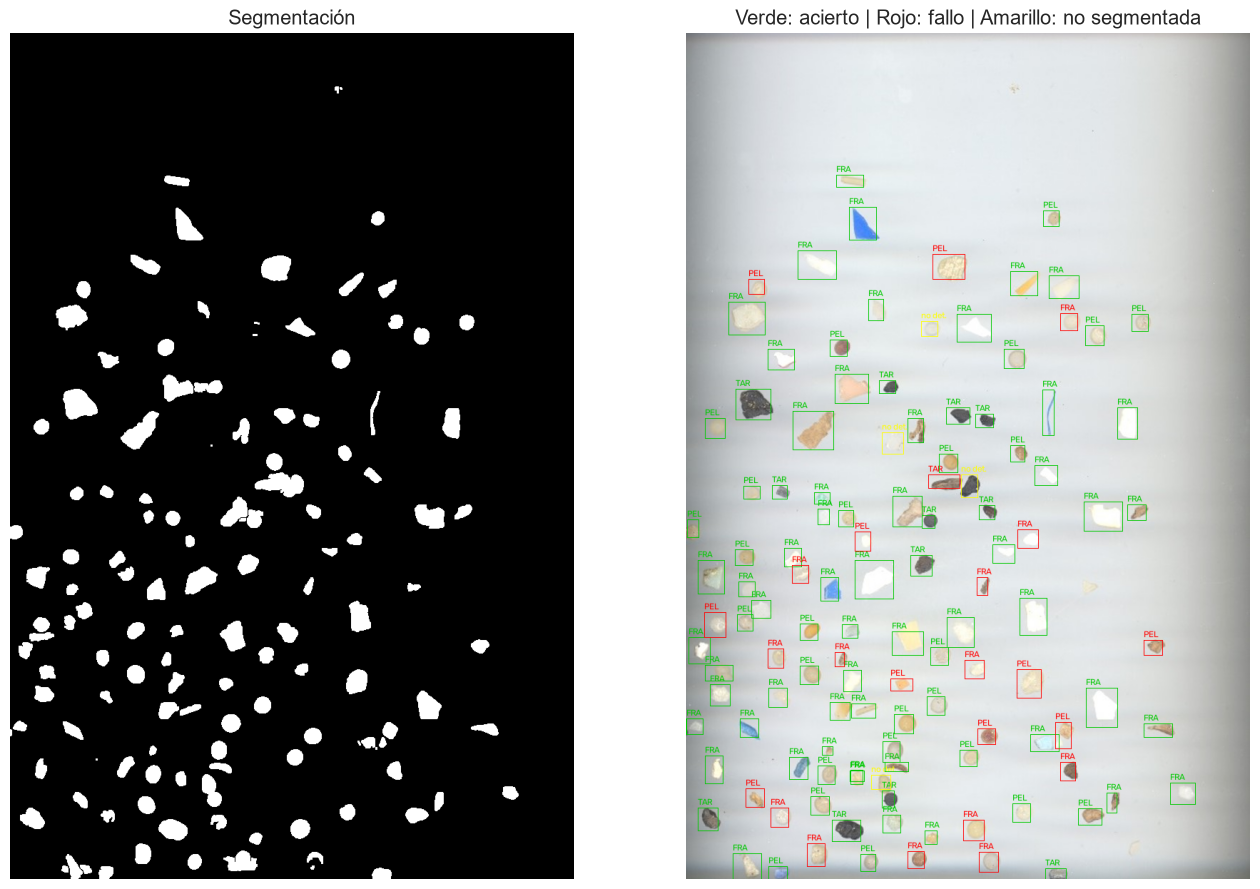

In [33]:
vis = img_test.copy()
for (etiqueta, x1, y1, x2, y2), idx in zip(anotaciones, pares):
    if idx is None:
        color, texto = (0, 255, 255), 'no det.'
    else:
        pred = pred_todas[idx]
        color = (0, 200, 0) if pred == etiqueta else (0, 0, 255)
        texto = pred
    cv2.rectangle(vis, (x1, y1), (x2, y2), color, 1)
    cv2.putText(vis, texto, (x1, max(y1 - 4, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1)

plt.figure(figsize=(16, 11))
plt.subplot(1, 2, 1); plt.axis("off"); plt.imshow(binaria_t, cmap='gray'); plt.title('Segmentación')
plt.subplot(1, 2, 2); plt.axis("off"); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('Verde: acierto | Rojo: fallo | Amarillo: no segmentada')
plt.show()

### Conclusión

- **Detección:** con el método anterior (gris + umbral adaptativo, `AREA_MIN=150`) solo se encontraban **49 de las 120** partículas anotadas; con el umbral adaptativo y `AREA_MIN=80` llegaban a 60. La segmentación por distancia Lab al fondo + histéresis encuentra **116/120**, incluidos los fragmentos blancos y pellets claros. Las 4 que faltan son partículas casi transparentes o pegadas a otra.
- **Clasificación (sobre las 116 detectadas):** accuracy ≈ 0,78 (precisión 0,80, recall 0,78, F1 0,77). Contando las no detectadas como fallo sobre las 120 anotadas: ≈ 0,76, frente a ≈ 0,31 del método anterior (37 aciertos de 120).
- **Por clase:** FRA recall 0,94 · PEL recall 0,65 · TAR precisión 1,00 pero recall 0,47. Sigue habiendo sesgo hacia FRA: los pellets muy claros pierden redondez al segmentarse y los TAR marrones/alargados no son tan oscuros como los del entrenamiento.
- **Limitación principal:** el entrenamiento es de cámara y el test de escáner (el color y el contraste cambian). Las características de color relativas al fondo lo mitigan, pero no lo eliminan.
- **Probado y descartado:** cierre morfológico grande (une partículas vecinas, -5 detecciones) y características de tono normalizado (empeoran PEL).
- **Mejoras posibles:** entrenar con alguna partícula del propio escáner, separar partículas pegadas con *watershed* y añadir textura/brillo especular.

**Área mínima:** `AREA_MIN_MP = 80 px` a la resolución del test (≈ 1/5 del área mediana de un pellet). Por debajo de ~50 px solo aparece polvo/ruido; la partícula anotada más pequeña, salvo fibras finas, ronda los 150 px. Si cambia la resolución, escalar: `area_min ≈ 0,2 × área mediana de un pellet`.